In [ ]:
import pandas as pd

df = pd.read_csv("/content/styles.csv.xls", on_bad_lines="skip")
df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [ ]:
df = df[['productDisplayName',
         'articleType',
         'baseColour',
         'gender',
         'usage']]

df.dropna(inplace=True)

In [ ]:
def recommend(article):

    article = article.lower()

    if "shoe" in article:
        return ["Sports Socks",
                "Fitness Watch",
                "Water Bottle"]

    elif "shirt" in article:
        return ["Jeans",
                "Belt",
                "Sneakers"]

    elif "jeans" in article:
        return ["T-Shirt",
                "Casual Shoes",
                "Watch"]

    elif "watch" in article:
        return ["Bracelet",
                "Wallet"]

    elif "bag" in article:
        return ["Wallet",
                "Water Bottle"]

    else:
        return ["No recommendation available"]

In [ ]:
name = input("Enter Product Name: ").lower()

result = df[df["productDisplayName"].str.lower().str.contains(name)]
if len(result) == 0:
    print("Product Not Found")

else:

    product = result.iloc[0]

    print("Product Details")
    print("----------------")
    print("Name :", product['productDisplayName'])
    print("Category :", product['articleType'])
    print("Colour :", product['baseColour'])
    print("Gender :", product['gender'])
    print("Usage :", product['usage'])
    items = recommend(product['articleType'])

print("\nRecommended Products")

for i in items:
    print("✓", i)

Enter Product Name: blue shirt
Product Details
----------------
Name : Turtle Check Men Navy Blue Shirt
Category : Shirts
Colour : Navy Blue
Gender : Men
Usage : Casual

Recommended Products
✓ Jeans
✓ Belt
✓ Sneakers


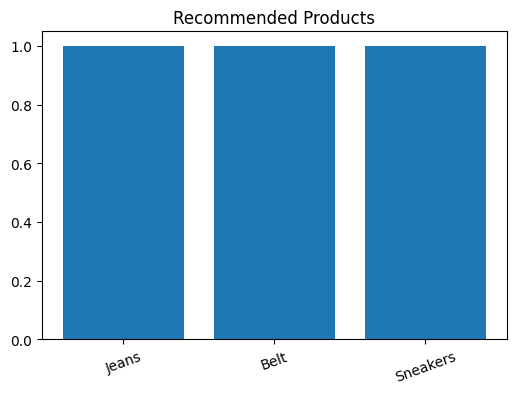

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(items, [1]*len(items))
plt.title("Recommended Products")
plt.xticks(rotation=20)
plt.show()